# Task 1 – Data Preparation & Exploration
**Dataset:** Airline passenger satisfaction (`test.csv`) | **Task type:** binary classification | **Target:** `satisfaction`

**Notebook outline**
1. Data Understanding
2. Data Cleaning (missing values, duplicates, outliers)
3. Exploratory Data Analysis (univariate, feature vs target, feature-to-feature, correlation, groupby)
4. Summary of main findings

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100

# 1. Data Understanding
*Explore the dataset before changing any values.*

### 1.1 Read Data

In [2]:
PATH = "data/test.csv"
df_raw = pd.read_csv(PATH)
print("Loaded successfully")
df = df_raw.copy()          # all later work is done on a copy; df_raw stays untouched
df.head()

Loaded successfully


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,19556,Female,Loyal Customer,52,Business travel,Eco,160,5,4,3,4,3,4,3,5,5,5,5,2,5,5,50,44.0,satisfied
1,1,90035,Female,Loyal Customer,36,Business travel,Business,2863,1,1,3,1,5,4,5,4,4,4,4,3,4,5,0,0.0,satisfied
2,2,12360,Male,disloyal Customer,20,Business travel,Eco,192,2,0,2,4,2,2,2,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied
3,3,77959,Male,Loyal Customer,44,Business travel,Business,3377,0,0,0,2,3,4,4,1,1,1,1,3,1,4,0,6.0,satisfied
4,4,36875,Female,Loyal Customer,49,Business travel,Eco,1182,2,3,4,3,4,1,2,2,2,2,2,4,2,4,0,20.0,satisfied


### 1.2 Random Sample of Rows

In [3]:
df.sample(8, random_state=42)

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
13047,13047,88810,Female,disloyal Customer,20,Business travel,Eco Plus,404,2,2,2,4,3,2,3,3,4,4,4,3,4,3,0,0.0,neutral or dissatisfied
14975,14975,44461,Male,Loyal Customer,51,Business travel,Business,1627,1,1,1,1,2,4,5,4,4,4,5,5,4,2,0,0.0,satisfied
12642,12642,73353,Male,Loyal Customer,41,Business travel,Eco,1012,3,5,5,5,3,3,3,3,3,5,3,2,4,3,1,1.0,neutral or dissatisfied
23011,23011,64429,Male,Loyal Customer,49,Business travel,Business,3985,3,3,3,3,5,4,5,4,4,5,4,4,4,4,1,0.0,satisfied
13308,13308,65486,Male,Loyal Customer,23,Personal Travel,Eco,1067,3,4,2,2,3,2,3,3,4,2,4,3,4,3,0,0.0,neutral or dissatisfied
9687,9687,12850,Female,Loyal Customer,48,Personal Travel,Eco,817,2,2,2,4,5,4,4,2,2,2,2,3,2,1,2,0.0,neutral or dissatisfied
6235,6235,53487,Male,Loyal Customer,59,Business travel,Eco,919,1,2,3,2,1,1,1,1,2,3,4,3,3,1,65,59.0,neutral or dissatisfied
16419,16419,46436,Male,Loyal Customer,50,Business travel,Business,2408,2,2,2,2,3,2,2,5,5,4,5,3,5,5,0,0.0,satisfied


### 1.3 Size of Data

In [4]:
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")

Rows: 25,976  |  Columns: 25


### 1.4 Information of Data (dtypes, non-null counts, memory)

In [5]:
df.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 25976 entries, 0 to 25975
Data columns (total 25 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Unnamed: 0                         25976 non-null  int64  
 1   id                                 25976 non-null  int64  
 2   Gender                             25976 non-null  str    
 3   Customer Type                      25976 non-null  str    
 4   Age                                25976 non-null  int64  
 5   Type of Travel                     25976 non-null  str    
 6   Class                              25976 non-null  str    
 7   Flight Distance                    25976 non-null  int64  
 8   Inflight wifi service              25976 non-null  int64  
 9   Departure/Arrival time convenient  25976 non-null  int64  
 10  Ease of Online booking             25976 non-null  int64  
 11  Gate location                      25976 non-null  int64  
 12  F

### 1.5 Column Names

In [6]:
for i, c in enumerate(df.columns):
    print(f"{i:2d}  {c!r}")

 0  'Unnamed: 0'
 1  'id'
 2  'Gender'
 3  'Customer Type'
 4  'Age'
 5  'Type of Travel'
 6  'Class'
 7  'Flight Distance'
 8  'Inflight wifi service'
 9  'Departure/Arrival time convenient'
10  'Ease of Online booking'
11  'Gate location'
12  'Food and drink'
13  'Online boarding'
14  'Seat comfort'
15  'Inflight entertainment'
16  'On-board service'
17  'Leg room service'
18  'Baggage handling'
19  'Checkin service'
20  'Inflight service'
21  'Cleanliness'
22  'Departure Delay in Minutes'
23  'Arrival Delay in Minutes'
24  'satisfaction'


**Observations**
- `Unnamed: 0` is a leftover index column from a previous export (it equals the row number) – not a real feature.
- Names are inconsistent: mixed case, spaces, slashes (`Departure/Arrival time convenient`) and the unclear `Departure Delay in Minutes`.
  They will be standardised to `snake_case` during cleaning.
- `id` is a passenger identifier and will not be a predictor.

### 1.6 Descriptive Statistics

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,25976.0,12987.500000,7498.769632,0.0,6493.75,12987.5,19481.25,25975.0
id,25976.0,65005.657992,37611.526647,17.0,32170.50,65319.5,97584.25,129877.0
Age,25976.0,39.620958,15.135685,7.0,27.00,40.0,51.00,85.0
Flight Distance,25976.0,1193.788459,998.683999,31.0,414.00,849.0,1744.00,4983.0
Inflight wifi service,25976.0,2.724746,1.335384,0.0,2.00,3.0,4.00,5.0
Departure/Arrival time convenient,25976.0,3.046812,1.533371,0.0,2.00,3.0,4.00,5.0
Ease of Online booking,25976.0,2.756775,1.412951,0.0,2.00,3.0,4.00,5.0
Gate location,25976.0,2.977094,1.282133,1.0,2.00,3.0,4.00,5.0
Food and drink,25976.0,3.215353,1.331506,0.0,2.00,3.0,4.00,5.0
Online boarding,25976.0,3.261665,1.355536,0.0,2.00,4.0,4.00,5.0


In [8]:
df.describe(include='object').T

/tmp/ipykernel_158/1760094569.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object').T


,count,unique,top,freq
Gender,25976,2,Female,13172
Customer Type,25976,2,Loyal Customer,21177
Type of Travel,25976,2,Business travel,18038
Class,25976,3,Business,12495
satisfaction,25976,2,neutral or dissatisfied,14573


### 1.7 Number of Unique Values

In [9]:
uniq = df.nunique().sort_values(ascending=False).to_frame("n_unique")
uniq["dtype"] = df.dtypes
uniq["pct_unique"] = (uniq["n_unique"] / len(df) * 100).round(2)
uniq

,n_unique,dtype,pct_unique
Unnamed: 0,25976,int64,100.00
id,25976,int64,100.00
Flight Distance,3281,int64,12.63
Arrival Delay in Minutes,320,float64,1.23
Departure Delay in Minutes,313,int64,1.20
Age,75,int64,0.29
Departure/Arrival time convenient,6,int64,0.02
Ease of Online booking,6,int64,0.02
Inflight wifi service,6,int64,0.02
Cleanliness,6,int64,0.02


**Observations**
- `id` and `Unnamed: 0` are unique per row (100% unique) → identifiers, not features.
- `Flight Distance` and the two delay columns are the only genuinely continuous variables with many unique values; `Age` has about 75 distinct values.
- The 14 service ratings each have only 5–6 distinct values (0–5) → ordinal.
- Categorical columns have very low cardinality (2–3 levels) so there is no high-cardinality problem.

### 1.8 Balance of Data (target distribution)

                         count  percent
satisfaction                           
neutral or dissatisfied  14573     56.1
satisfied                11403     43.9


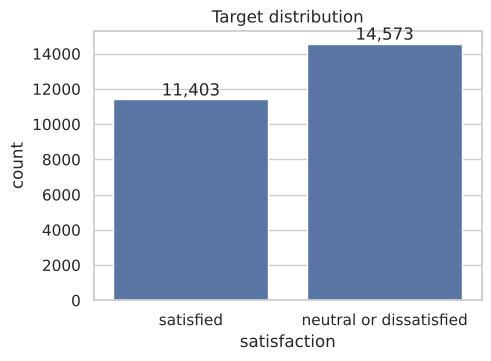

In [10]:
counts = df["satisfaction"].value_counts()
pct = df["satisfaction"].value_counts(normalize=True).mul(100).round(1)
print(pd.concat([counts, pct], axis=1, keys=["count", "percent"]))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="satisfaction", ax=ax)
ax.set_title("Target distribution")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

**Observation:** classes are mildly imbalanced (≈56 % neutral/dissatisfied vs ≈44 % satisfied). This is not severe, so no resampling is needed, but
stratified splitting and metrics such as F1 / ROC-AUC (not accuracy alone) should be used later.

# 2. Data Cleaning
*Every decision is documented.*

### 2.0 Standardise Column Names & Drop the Redundant Index

In [11]:
df = df.drop(columns=["Unnamed: 0"])          # row index leftover, no information

def clean_name(c):
    return (c.strip().lower()
             .replace("/", "_").replace(" ", "_").replace("-", "_"))

df.columns = [clean_name(c) for c in df.columns]
df = df.rename(columns={
    "departure_delay_in_minutes": "departure_delay_min",
    "arrival_delay_in_minutes": "arrival_delay_min",
    "type_of_travel": "travel_type",
})
print(list(df.columns))

['id', 'gender', 'customer_type', 'age', 'travel_type', 'class', 'flight_distance', 'inflight_wifi_service', 'departure_arrival_time_convenient', 'ease_of_online_booking', 'gate_location', 'food_and_drink', 'online_boarding', 'seat_comfort', 'inflight_entertainment', 'on_board_service', 'leg_room_service', 'baggage_handling', 'checkin_service', 'inflight_service', 'cleanliness', 'departure_delay_min', 'arrival_delay_min', 'satisfaction']


**Decision:** dropped `Unnamed: 0` (exact copy of the row index) and converted names to `snake_case` for easier, error-free coding.

### 2.1 Missing Values

In [12]:
miss = df.isna().sum()
miss = miss[miss > 0].to_frame("n_missing")
miss["pct"] = (miss["n_missing"] / len(df) * 100).round(3)
miss

,n_missing,pct
arrival_delay_min,83,0.32


In [13]:
# Are the missing rows special?
na_rows = df[df["arrival_delay_min"].isna()]
print("Departure delay of rows with missing arrival delay:")
print(na_rows["departure_delay_min"].describe().round(1))
print("\nCorrelation departure vs arrival delay:",
      round(df["departure_delay_min"].corr(df["arrival_delay_min"]), 3))

Departure delay of rows with missing arrival delay:
count     83.0
mean      39.6
std       79.7
min        0.0
25%        0.0
50%        8.0
75%       49.5
max      530.0
Name: departure_delay_min, dtype: float64

Correlation departure vs arrival delay: 0.965


Only `arrival_delay_min` has missing values (83 rows, 0.3 %). Options compared on the rows where the value is known
(mean absolute error of each rule at reproducing the real arrival delay):

In [14]:
known = df.dropna(subset=["arrival_delay_min"])
mae_median = (known["arrival_delay_min"] - known["arrival_delay_min"].median()).abs().mean()
mae_dep = (known["arrival_delay_min"] - known["departure_delay_min"]).abs().mean()
pd.DataFrame({"method": ["Fill with median", "Fill with departure delay"],
              "MAE (minutes)": [round(mae_median, 2), round(mae_dep, 2)]})

,method,MAE (minutes)
0,Fill with median,14.74
1,Fill with departure delay,4.98


**Decision:** impute the 83 missing values with the row's own `departure_delay_min`. A flight's arrival delay is almost the same as its departure delay
(correlation ≈ 0.96) and this rule reproduces the real values about 3× better than the median (MAE ≈ 5 vs ≈ 15 minutes). Dropping the rows would
waste data, and median imputation would badly understate the delay of the rows that left late (their mean departure delay is ≈ 40 min).

In [15]:
df["arrival_delay_min"] = df["arrival_delay_min"].fillna(df["departure_delay_min"])
print("Missing values left:", int(df.isna().sum().sum()))

Missing values left: 0


### 2.2 Duplicate Rows

In [16]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated passenger ids:", df['id'].duplicated().sum())
print("Duplicates ignoring id:", df.drop(columns='id').duplicated().sum())

Fully duplicated rows: 0
Duplicated passenger ids: 0
Duplicates ignoring id: 0


**Decision:** no duplicates of any kind, so nothing is removed. `id` is kept for now only as an identifier (it is excluded from analysis and modelling).

### 2.2b Consistency / Validity Checks

In [17]:
rating_cols = ['inflight_wifi_service', 'departure_arrival_time_convenient', 'ease_of_online_booking',
               'gate_location', 'food_and_drink', 'online_boarding', 'seat_comfort',
               'inflight_entertainment', 'on_board_service', 'leg_room_service',
               'baggage_handling', 'checkin_service', 'inflight_service', 'cleanliness']

print("Ratings outside 0-5:", int(((df[rating_cols] < 0) | (df[rating_cols] > 5)).sum().sum()))
print("Negative delays / distance:", int((df[['departure_delay_min','arrival_delay_min','flight_distance']] < 0).sum().sum()))
print("Age range:", df['age'].min(), "-", df['age'].max())
for c in ['gender', 'customer_type', 'travel_type', 'class', 'satisfaction']:
    print(f"{c:15s}", df[c].unique().tolist())

print("\nRows with rating = 0 ('not applicable') per column:")
(df[rating_cols] == 0).sum().loc[lambda s: s > 0].sort_values(ascending=False)

Ratings outside 0-5:

 0
Negative delays / distance: 0
Age range: 7 - 85
gender          ['Female', 'Male']
customer_type   ['Loyal Customer', 'disloyal Customer']
travel_type     ['Business travel', 'Personal Travel']
class           ['Eco', 'Business', 'Eco Plus']
satisfaction    ['satisfied', 'neutral or dissatisfied']

Rows with rating = 0 ('not applicable') per column:


departure_arrival_time_convenient    1381
ease_of_online_booking               1195
inflight_wifi_service                 813
online_boarding                       652
leg_room_service                      126
food_and_drink                         25
inflight_entertainment                  4
on_board_service                        2
inflight_service                        2
cleanliness                             2
dtype: int64

**Observations**
- All values are within valid ranges; category labels are consistent (no typos or mixed spellings).
- In the rating columns **0 means "not applicable / not rated"**, not "worst" (scale is 1-5). It occurs mainly for wifi, online booking, online boarding and
  time convenience. **Decision:** keep the 0 as-is in the cleaned file (it is genuine information, e.g. a passenger who never used online boarding) and
  handle it explicitly in feature engineering later.

### 2.3 Outlier Detection

In [18]:
num_cols = ['age', 'flight_distance', 'departure_delay_min', 'arrival_delay_min']

def iqr_summary(frame, cols):
    rows = []
    for c in cols:
        q1, q3 = frame[c].quantile([.25, .75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = ((frame[c] < lo) | (frame[c] > hi)).sum()
        rows.append([c, lo, hi, n, round(n / len(frame) * 100, 2), frame[c].max(),
                     frame[c].quantile(.99), round(frame[c].skew(), 2)])
    return pd.DataFrame(rows, columns=["feature", "lower_fence", "upper_fence", "n_outliers",
                                       "pct", "max", "p99", "skew"]).set_index("feature")

iqr_summary(df, num_cols)

,lower_fence,upper_fence,n_outliers,pct,max,p99,skew
feature,,,,,,,
age,-9.0,87.0,0,0.00,85.0,70.00,-0.00
flight_distance,-1581.0,3739.0,584,2.25,4983.0,3889.00,1.10
departure_delay_min,-18.0,30.0,3569,13.74,1128.0,168.00,7.19
arrival_delay_min,-19.5,32.5,3563,13.72,1115.0,173.25,6.97


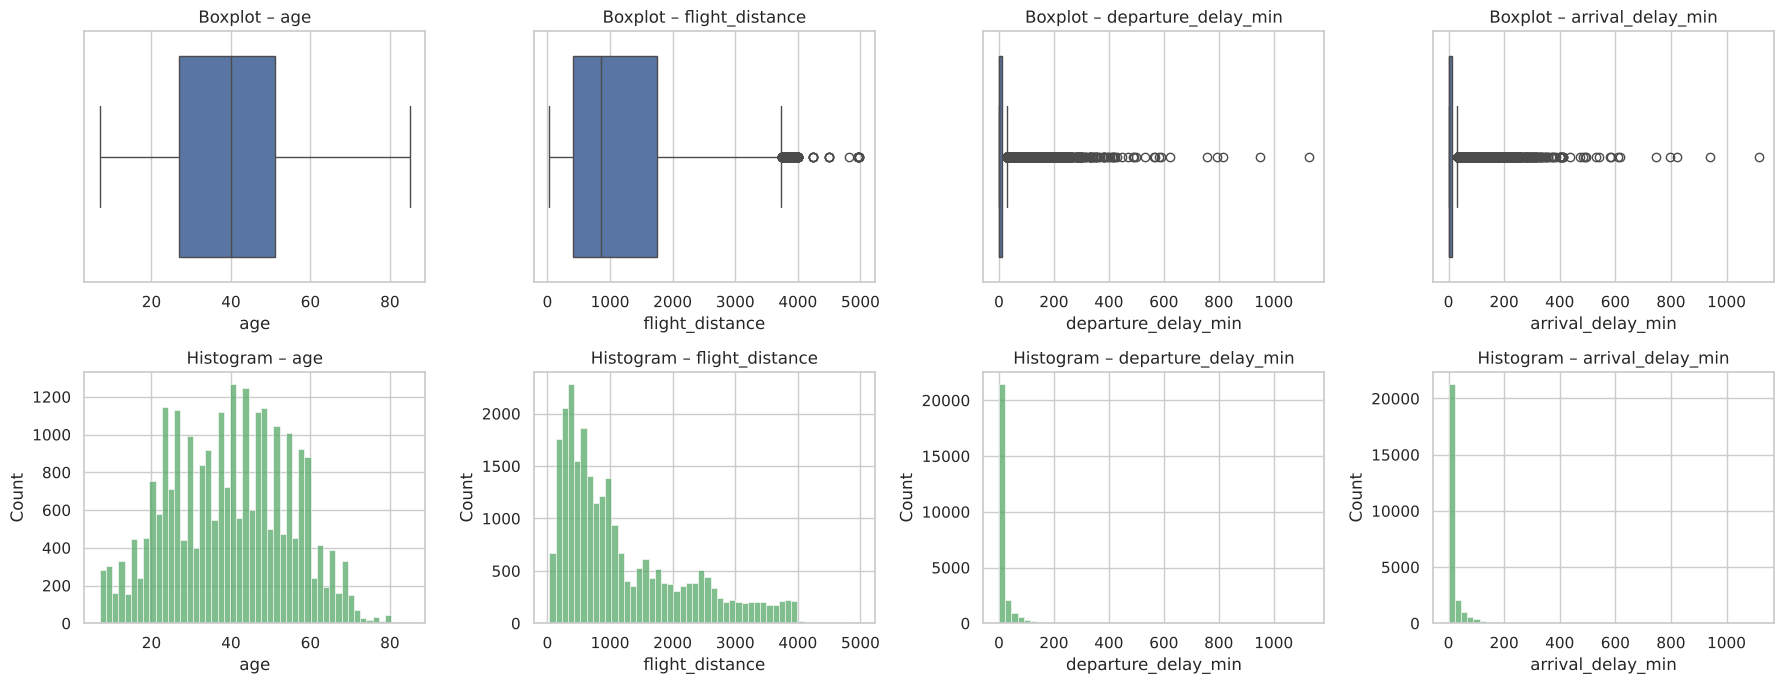

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, c in enumerate(num_cols):
    sns.boxplot(x=df[c], ax=axes[0, i], color="#4c72b0")
    axes[0, i].set_title(f"Boxplot – {c}")
    sns.histplot(df[c], bins=50, ax=axes[1, i], color="#55a868")
    axes[1, i].set_title(f"Histogram – {c}")
plt.tight_layout(); plt.show()

In [20]:
# z-score view for the same features (|z| > 3)
z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()
(z.abs() > 3).sum().to_frame("n_|z|>3")

,n_|z|>3
age,0
flight_distance,20
departure_delay_min,504
arrival_delay_min,506


**Observations**
- `age`: no outliers (7–85, symmetric).
- `flight_distance`: ≈ 2 % flagged, up to ≈ 5,000 – these are valid long-haul flights.
- `departure_delay_min` / `arrival_delay_min`: ≈ 14 % flagged by IQR, extremely right-skewed (skew ≈ 7, max ≈ 1,100 min ≈ 18 h).
  Most flights have delay 0, so the IQR fence (≈ 30 min) is very tight and flags many perfectly normal moderate delays.

### 2.4 Outlier Treatment – Comparing Options

In [21]:
col = "departure_delay_min"
s = df[col]
p99 = s.quantile(.99)
options = {
    "Keep (original)":               s,
    "Remove IQR outliers":           s[s <= s.quantile(.75) + 1.5 * (s.quantile(.75) - s.quantile(.25))],
    "Cap at 99th percentile":        s.clip(upper=p99),
    "log1p transform":               np.log1p(s),
}
cmp = pd.DataFrame({
    name: {"rows": len(v), "mean": v.mean(), "std": v.std(), "max": v.max(), "skew": v.skew()}
    for name, v in options.items()
}).T.round(2)
cmp

,rows,mean,std,max,skew
Keep (original),25976.0,14.31,37.42,1128.00,7.19
Remove IQR outliers,22407.0,3.71,7.02,30.00,2.04
Cap at 99th percentile,25976.0,13.34,29.25,168.00,3.24
log1p transform,25976.0,1.22,1.61,7.03,0.92


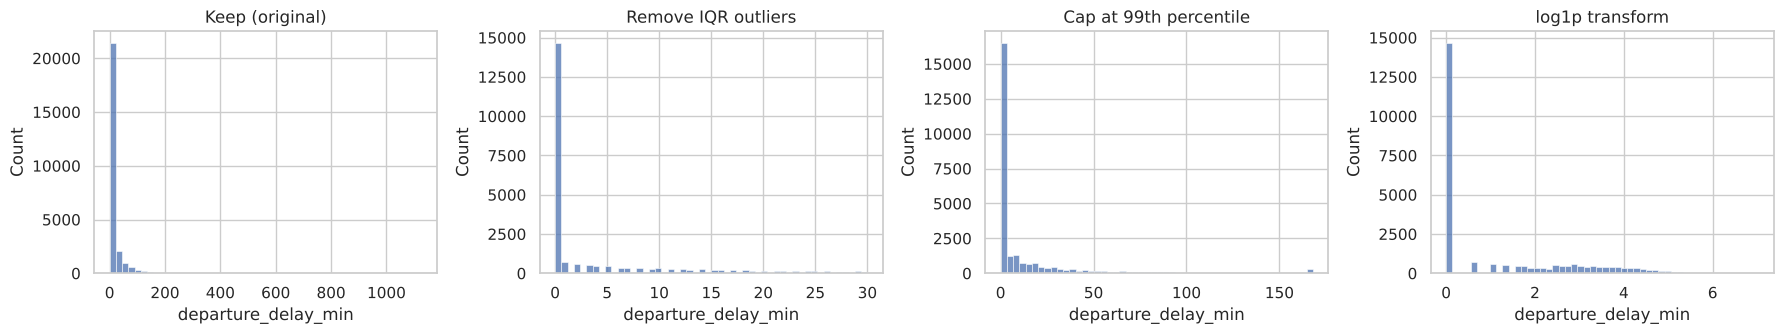

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, (name, v) in zip(axes, options.items()):
    sns.histplot(v, bins=50, ax=ax); ax.set_title(name)
plt.tight_layout(); plt.show()

In [23]:
# Do the extreme delays carry information about the target?
tmp = df.assign(extreme=df['departure_delay_min'] > p99)
tmp.groupby('extreme')['satisfaction'].apply(lambda x: (x == 'satisfied').mean()).round(3).to_frame("share_satisfied")

,share_satisfied
extreme,
False,0.44
True,0.35


**Decision (documented):**

| Option | Verdict |
|---|---|
| **Remove** | Rejected – would delete ≈ 14 % of the rows (≈ 3,500 passengers) that are real flights and distort the delay distribution. |
| **Cap at p99** | Possible, but throws away real information and changes the data permanently. |
| **log1p transform** | Best way to reduce skew (7.2 → 0.9) while keeping every row. This is a *transformation*, so it belongs to feature engineering / modelling rather than to cleaning. |
| **Keep** | ✅ **Chosen for the cleaned dataset.** The extremes are genuine events (no data-entry errors found), and tree-based models are insensitive to them. |

So: **no values are removed or capped in the cleaned file**; the skew will be handled with a `log1p` transform (and scaling) in the next task.
`age` and `flight_distance` are also kept unchanged.

### 2.5 Save the Cleaned Dataset

In [24]:
df_clean = df.copy()
df_clean["target"] = (df_clean["satisfaction"] == "satisfied").astype(int)   # 1 = satisfied (kept next to original text label)
df_clean.to_csv("/mnt/user-data/outputs/cleaned_data.csv", index=False)

print("Shape before cleaning:", df_raw.shape, "→ after:", df_clean.shape)
print("Missing values:", int(df_clean.isna().sum().sum()), "| duplicates:", int(df_clean.duplicated().sum()))
df_clean.head()

Shape before cleaning: (25976, 25) → after: (25976, 25)
Missing values: 0 | duplicates: 0


,id,gender,customer_type,age,travel_type,class,flight_distance,inflight_wifi_service,departure_arrival_time_convenient,ease_of_online_booking,gate_location,food_and_drink,online_boarding,seat_comfort,inflight_entertainment,on_board_service,leg_room_service,baggage_handling,checkin_service,inflight_service,cleanliness,departure_delay_min,arrival_delay_min,satisfaction,target
0,19556,Female,Loyal Customer,52,Business travel,Eco,160,5,4,3,4,3,4,3,5,5,5,5,2,5,5,50,44.0,satisfied,1
1,90035,Female,Loyal Customer,36,Business travel,Business,2863,1,1,3,1,5,4,5,4,4,4,4,3,4,5,0,0.0,satisfied,1
2,12360,Male,disloyal Customer,20,Business travel,Eco,192,2,0,2,4,2,2,2,2,4,1,3,2,2,2,0,0.0,neutral or dissatisfied,0
3,77959,Male,Loyal Customer,44,Business travel,Business,3377,0,0,0,2,3,4,4,1,1,1,1,3,1,4,0,6.0,satisfied,1
4,36875,Female,Loyal Customer,49,Business travel,Eco,1182,2,3,4,3,4,1,2,2,2,2,2,4,2,4,0,20.0,satisfied,1


### Cleaning Summary
| Issue | Finding | Action |
|---|---|---|
| Redundant column | `Unnamed: 0` = row index | Dropped |
| Column names | spaces / slashes / mixed case | Converted to `snake_case`, shortened 3 names |
| Missing values | 83 in `arrival_delay_min` (0.3 %) | Filled with the row's departure delay |
| Duplicates | 0 | None needed |
| Invalid values | none; 0 in ratings = "not applicable" | Kept, documented |
| Outliers | delays & distance are skewed but genuine | Kept; `log1p` planned for modelling |

# 3. Exploratory Data Analysis (EDA)

In [25]:
df = df_clean.copy()
cat_cols = ['gender', 'customer_type', 'travel_type', 'class']
num_cols = ['age', 'flight_distance', 'departure_delay_min', 'arrival_delay_min']

## 3.1 Univariate Analysis

### Categorical features

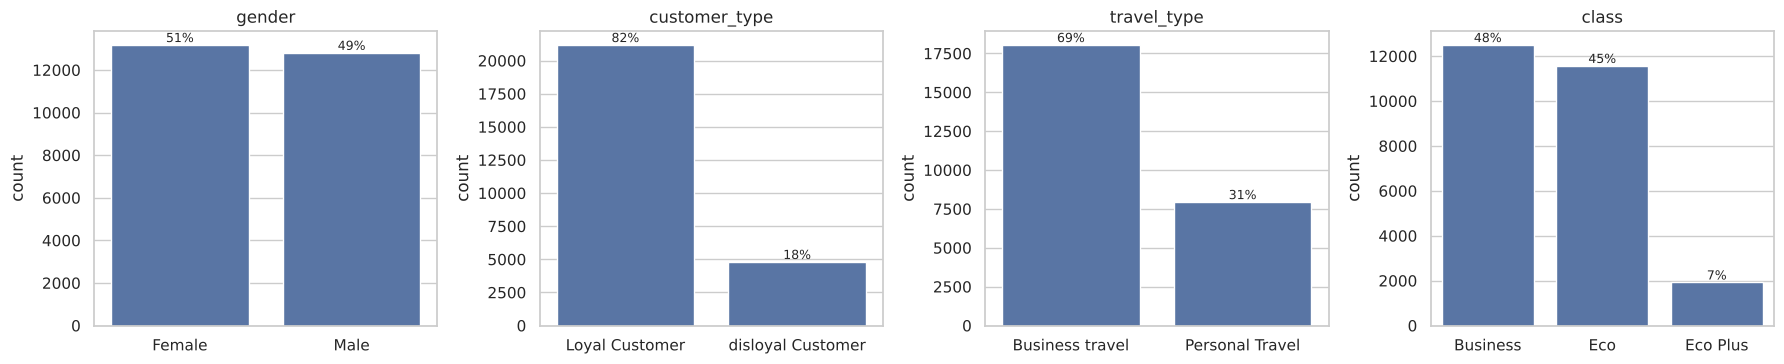

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, cat_cols):
    order = df[c].value_counts().index
    sns.countplot(data=df, x=c, order=order, ax=ax)
    ax.set_title(c); ax.set_xlabel("")
    for p in ax.patches:
        ax.annotate(f"{p.get_height()/len(df):.0%}", (p.get_x()+p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

**Observations:** gender is balanced (≈ 51/49). About 82 % are loyal customers and ≈ 69 % travel for business. Business and Eco classes are roughly equal
(≈ 48 % / 45 %); Eco Plus is small (≈ 7 %).

### Numerical features

In [27]:
df[num_cols].agg(['mean', 'median', 'std', 'min', 'max', 'skew']).T.round(2)

,mean,median,std,min,max,skew
age,39.62,40.0,15.14,7.0,85.0,-0.00
flight_distance,1193.79,849.0,998.68,31.0,4983.0,1.10
departure_delay_min,14.31,0.0,37.42,0.0,1128.0,7.19
arrival_delay_min,14.82,0.0,37.75,0.0,1115.0,6.97


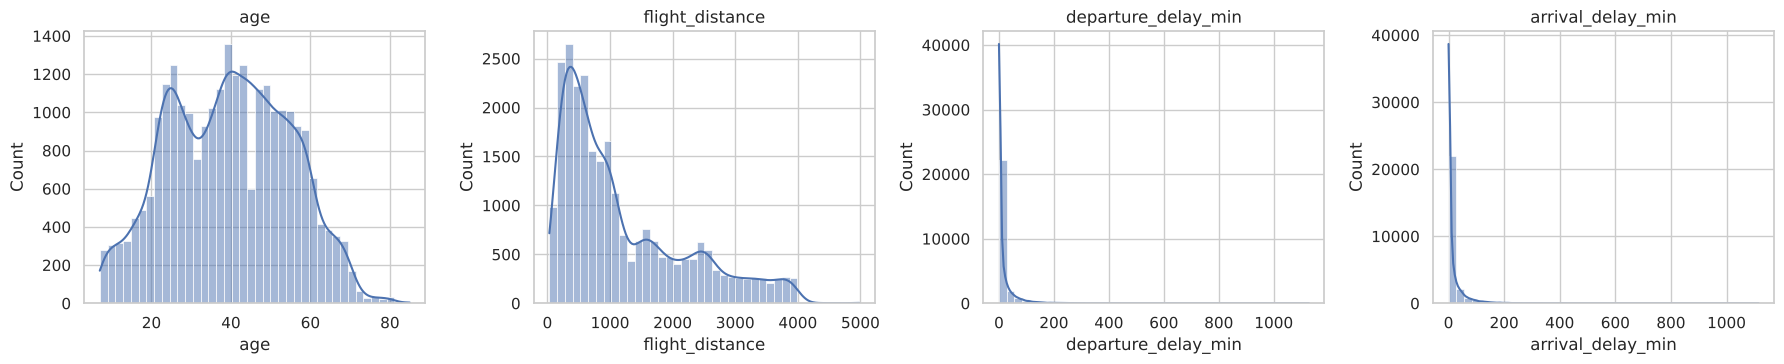

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, num_cols):
    sns.histplot(df[c], bins=40, kde=True, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

**Observations:** age is close to a normal curve (mean ≈ 40 = median). Flight distance is right-skewed (many short flights, median ≈ 850 km vs mean ≈ 1,190).
Both delay columns are extremely skewed: more than half of the flights have no delay at all (median = 0) with a long tail.

### Service ratings (0–5)

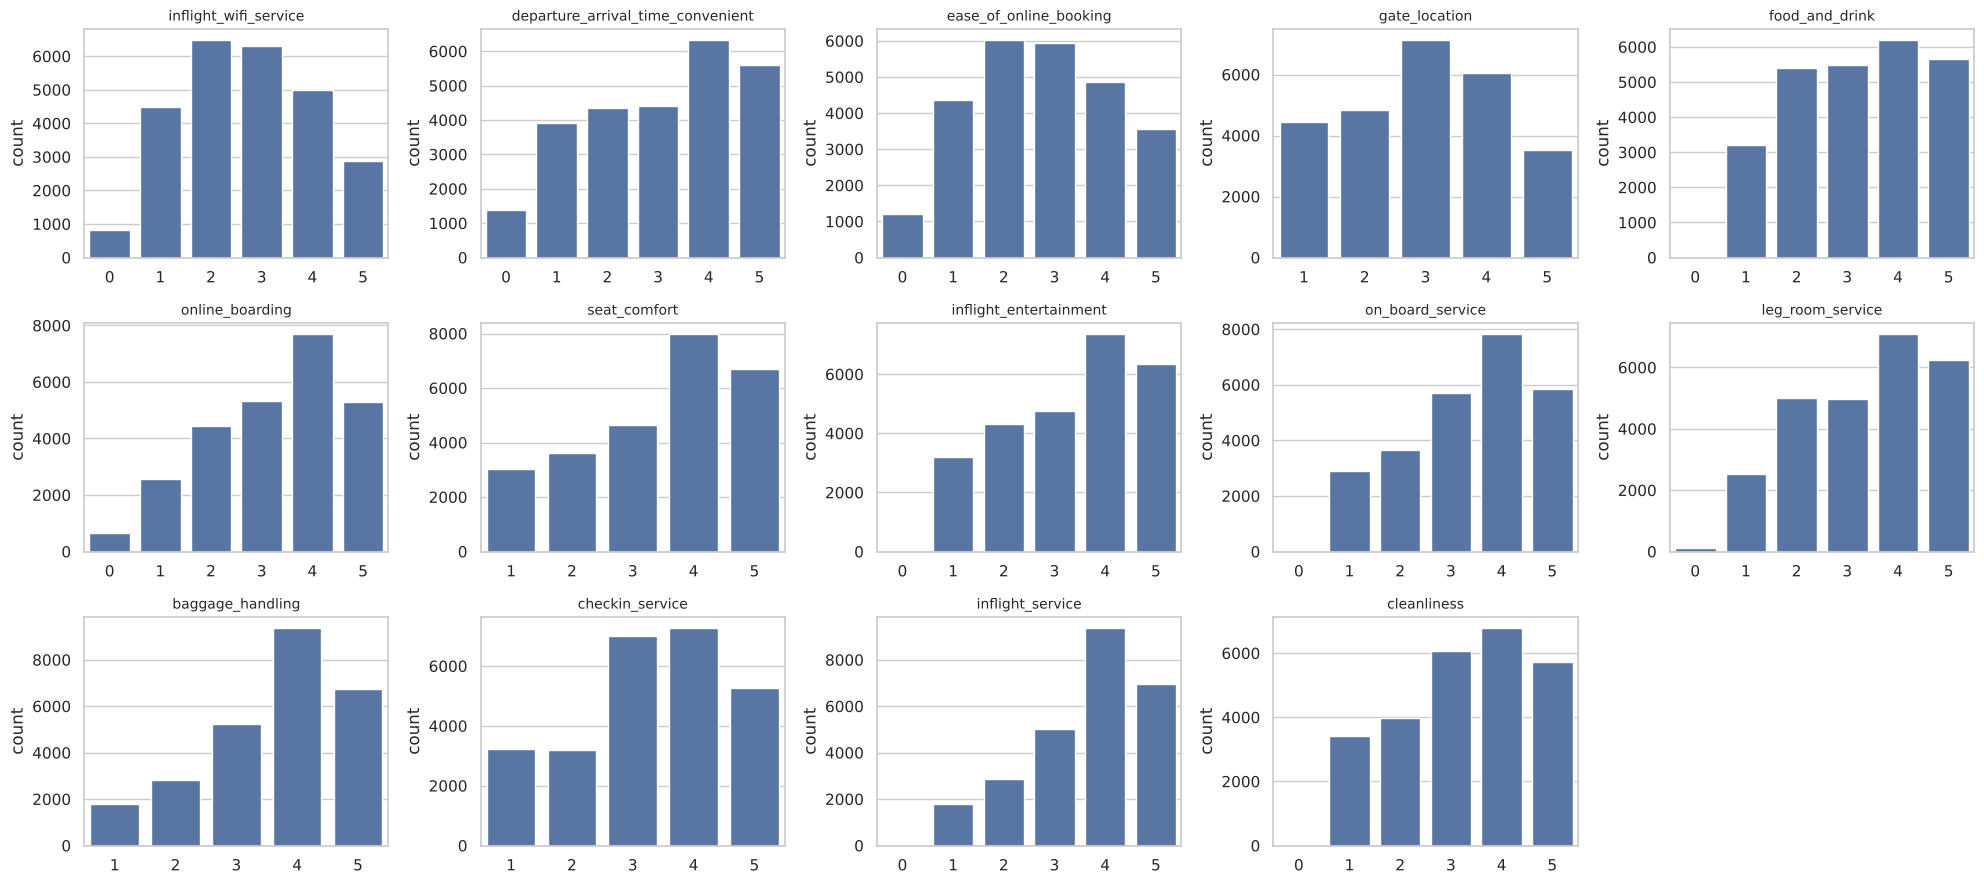

,mean,median
inflight_wifi_service,2.72,3.0
ease_of_online_booking,2.76,3.0
gate_location,2.98,3.0
departure_arrival_time_convenient,3.05,3.0
food_and_drink,3.22,3.0
online_boarding,3.26,4.0
cleanliness,3.29,3.0
checkin_service,3.31,3.0
leg_room_service,3.35,4.0
inflight_entertainment,3.36,4.0


In [29]:
fig, axes = plt.subplots(3, 5, figsize=(20, 9))
for ax, c in zip(axes.ravel(), rating_cols):
    sns.countplot(data=df, x=c, ax=ax, color="#4c72b0"); ax.set_title(c, fontsize=10); ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()
df[rating_cols].agg(['mean', 'median']).T.round(2).sort_values('mean')

**Observations:** ratings are mostly 3–5. `inflight_wifi_service`, `ease_of_online_booking` and `gate_location` have the lowest average scores (≈ 2.7–3.0);
`inflight_service` and `baggage_handling` the highest (≈ 3.6). The 0 ("not applicable") category is visible in the wifi, booking, time-convenience and online-boarding charts.

## 3.2 Feature vs. Target Analysis

### Categorical features vs satisfaction

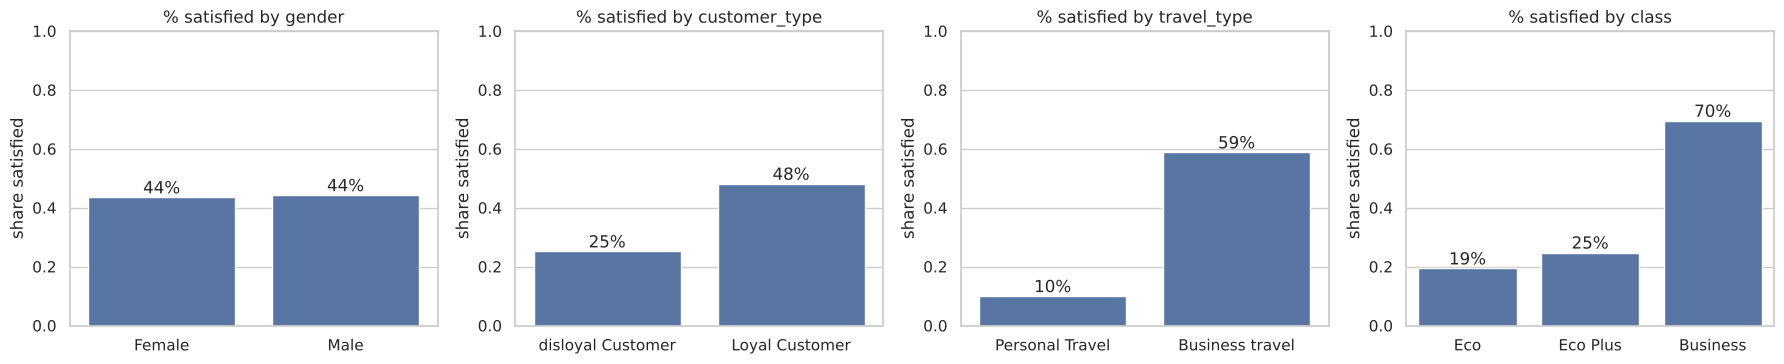

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, cat_cols):
    rate = df.groupby(c)['target'].mean().sort_values()
    sns.barplot(x=rate.index, y=rate.values, ax=ax)
    ax.set_title(f"% satisfied by {c}"); ax.set_ylim(0, 1); ax.set_xlabel(""); ax.set_ylabel("share satisfied")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.0%}", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()

In [31]:
from scipy.stats import chi2_contingency
rows = []
for c in cat_cols:
    chi2, p, _, _ = chi2_contingency(pd.crosstab(df[c], df['target']))
    rows.append([c, round(chi2, 1), p])
pd.DataFrame(rows, columns=['feature', 'chi2', 'p_value']).set_index('feature')

,chi2,p_value
feature,,
gender,1.4,2.421285e-01
customer_type,837.3,4.297553e-184
travel_type,5334.8,0.000000e+00
class,6435.0,0.000000e+00


**Observations:** `class` and `travel_type` are the strongest categorical drivers: ≈ 70 % of Business-class passengers are satisfied vs ≈ 19 % in Eco, and
business travellers are far more satisfied than personal travellers (≈ 59 % vs ≈ 10 %). Loyal customers are about twice as satisfied as disloyal ones (≈ 48 % vs ≈ 25 %).
Gender shows almost no difference (≈ 44 % vs ≈ 44 %).

### Numerical features vs satisfaction

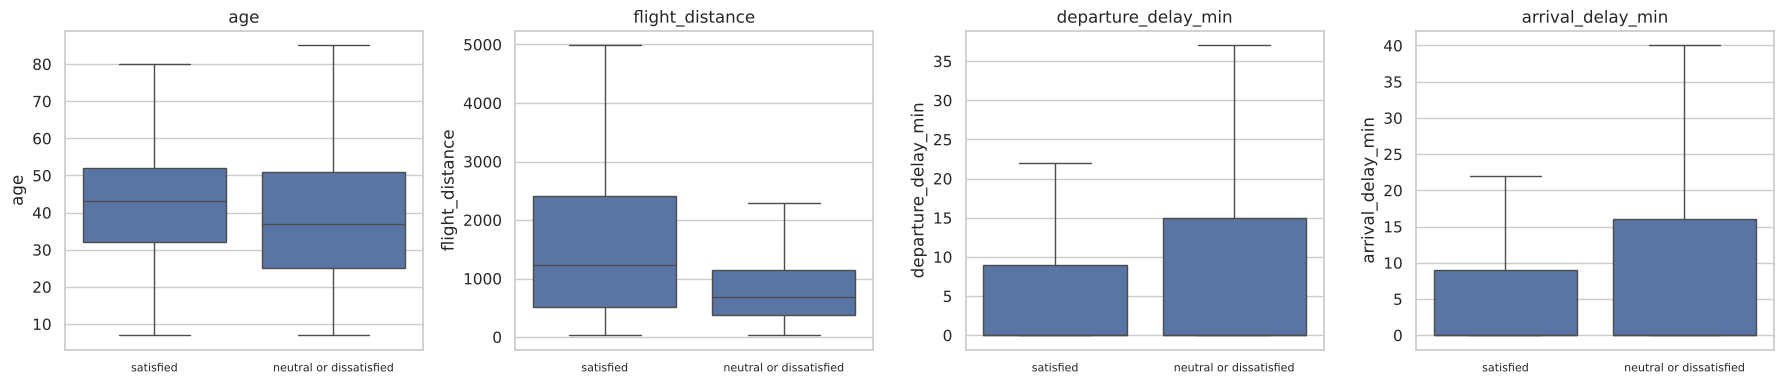

,age,flight_distance,departure_delay_min,arrival_delay_min
satisfaction,,,,
neutral or dissatisfied,37.0,679.0,0.0,0.0
satisfied,43.0,1237.0,0.0,0.0


In [32]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=df, x='satisfaction', y=c, ax=ax, showfliers=False)
    ax.set_title(c); ax.set_xlabel("")
    ax.tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()
df.groupby('satisfaction')[num_cols].median()

**Observations:** satisfied passengers are somewhat older and fly longer distances. Delays look similar for both groups (outliers hidden in the plot;
medians are 0 for both), so delays are only weakly related to satisfaction. The 1 % most-delayed departures are somewhat less satisfied (≈ 35 % vs ≈ 44 %), but that is a small group.

### Service ratings vs satisfaction

In [33]:
mean_by_target = df.groupby('satisfaction')[rating_cols].mean().T.round(2)
mean_by_target['gap'] = (mean_by_target['satisfied'] - mean_by_target['neutral or dissatisfied']).round(2)
mean_by_target.sort_values('gap', ascending=False)

satisfaction,neutral or dissatisfied,satisfied,gap
online_boarding,2.67,4.02,1.35
inflight_entertainment,2.89,3.96,1.07
seat_comfort,3.04,3.97,0.93
cleanliness,2.92,3.76,0.84
on_board_service,3.02,3.85,0.83
leg_room_service,2.99,3.81,0.82
inflight_wifi_service,2.39,3.15,0.76
checkin_service,3.04,3.66,0.62
baggage_handling,3.37,3.97,0.60
inflight_service,3.39,3.98,0.59


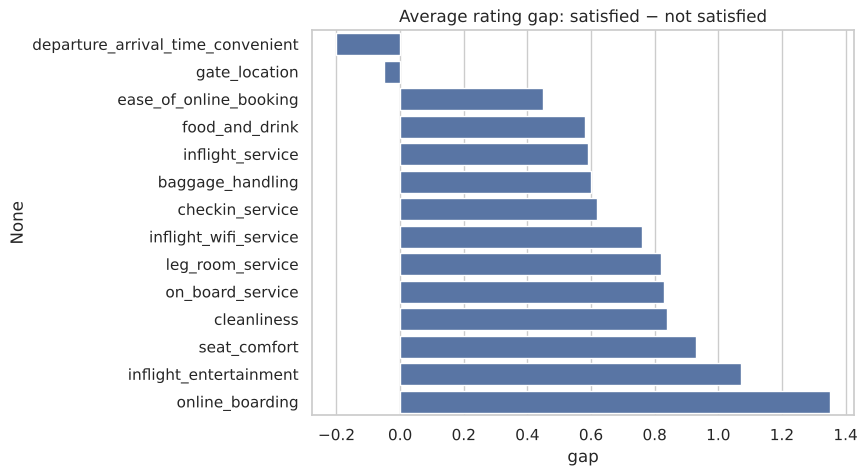

In [34]:
gap = mean_by_target['gap'].sort_values()
plt.figure(figsize=(7, 5))
sns.barplot(x=gap.values, y=gap.index, color="#4c72b0")
plt.title("Average rating gap: satisfied − not satisfied"); plt.xlabel("gap"); plt.show()

**Observations:** `online_boarding` (gap ≈ 1.35), `inflight_entertainment`, `seat_comfort`, `cleanliness` and `on_board_service` show the biggest rating gaps between satisfied and
unsatisfied passengers. `gate_location` and `departure_arrival_time_convenient` show no positive gap (≈ 0 and slightly negative), so they are weak signals.

## 3.3 Feature-to-Feature Analysis

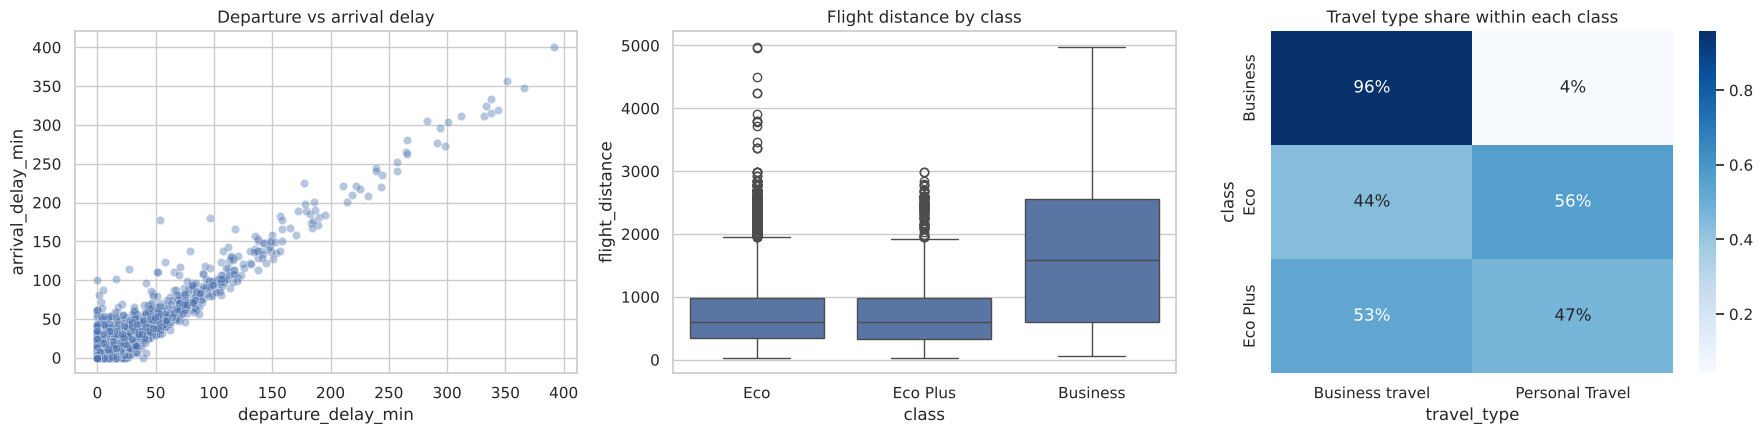

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.scatterplot(data=df.sample(4000, random_state=1), x='departure_delay_min', y='arrival_delay_min', alpha=.4, ax=axes[0])
axes[0].set_title("Departure vs arrival delay")
sns.boxplot(data=df, x='class', y='flight_distance', order=['Eco', 'Eco Plus', 'Business'], ax=axes[1])
axes[1].set_title("Flight distance by class")
sns.heatmap(pd.crosstab(df['class'], df['travel_type'], normalize='index'), annot=True, fmt='.0%', cmap='Blues', ax=axes[2])
axes[2].set_title("Travel type share within each class")
plt.tight_layout(); plt.show()

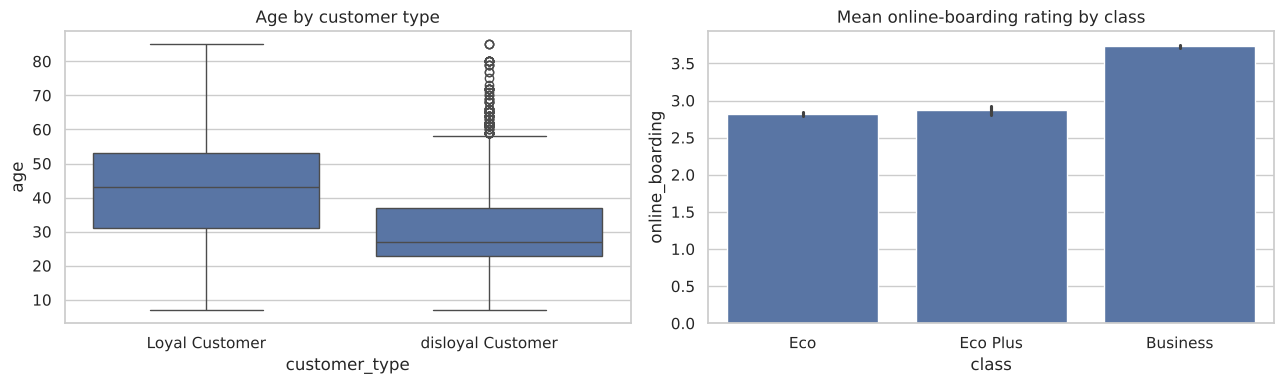

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x='customer_type', y='age', ax=axes[0]); axes[0].set_title("Age by customer type")
sns.barplot(data=df, x='class', y='online_boarding', order=['Eco', 'Eco Plus', 'Business'], ax=axes[1])
axes[1].set_title("Mean online-boarding rating by class")
plt.tight_layout(); plt.show()

**Observations**
- Departure and arrival delay are almost perfectly linear → heavily **redundant** (one of them may be dropped or combined later).
- Flight distance depends on class: Business class flies much longer routes (median ≈ 1,590 vs ≈ 600 for Eco / Eco Plus).
- Class and travel type overlap strongly: 96 % of Business-class passengers travel for business, whereas Eco is split ≈ 44/56. These two predictors carry related information.

## 3.4 Correlation Analysis

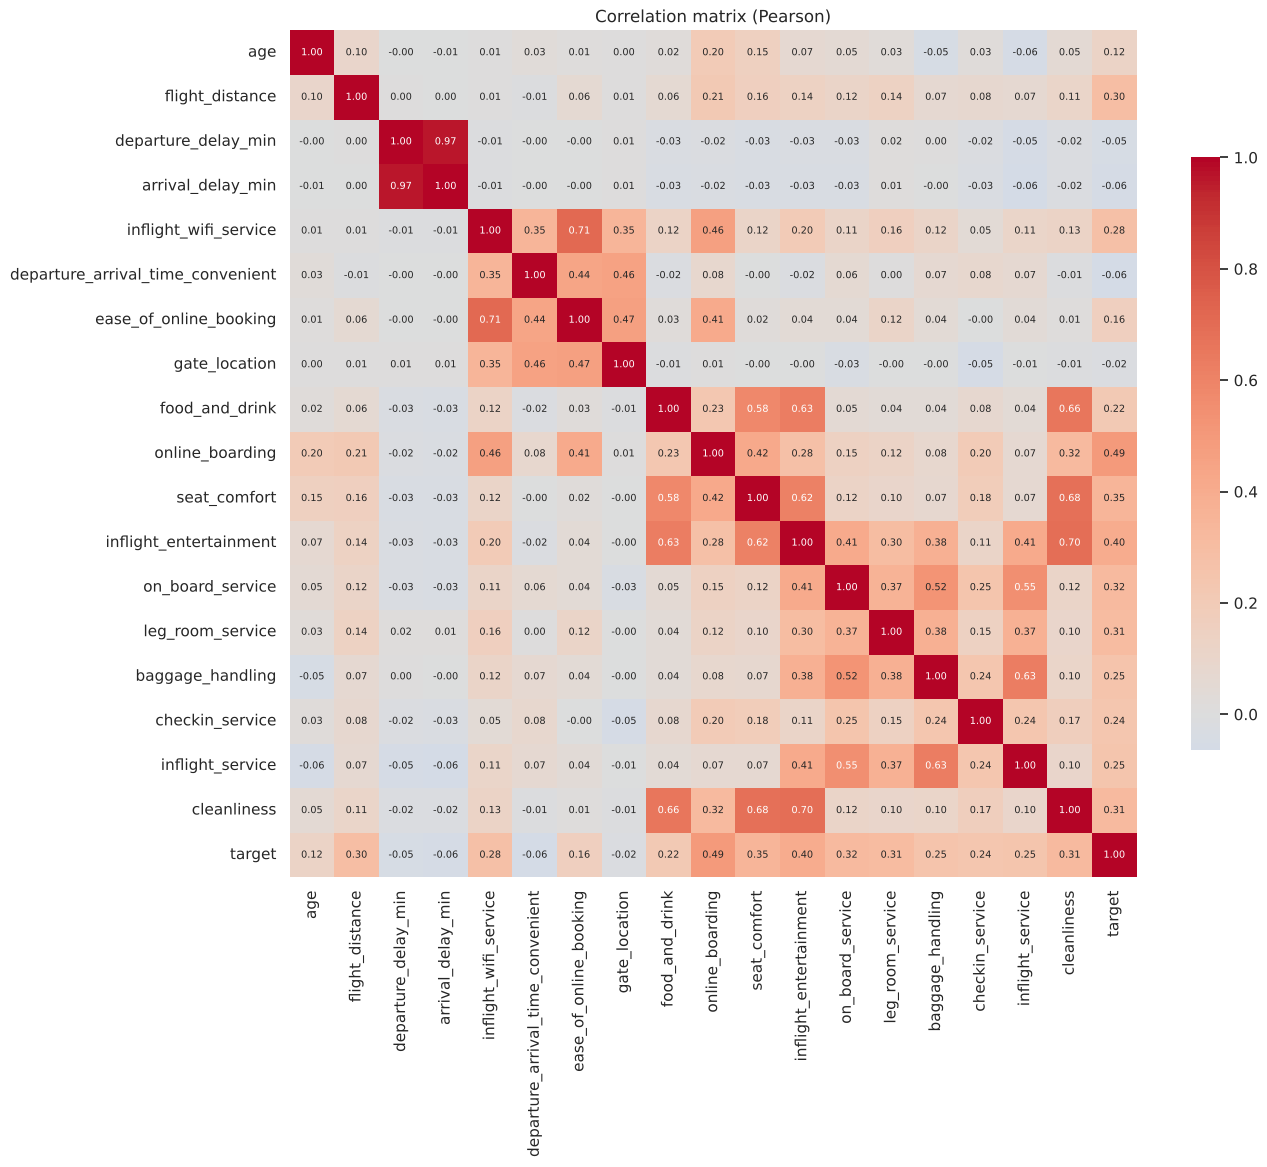

In [37]:
corr_cols = num_cols + rating_cols + ['target']
corr = df[corr_cols].corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, square=True, cbar_kws={"shrink": .7})
plt.title("Correlation matrix (Pearson)"); plt.show()

In [38]:
corr['target'].drop('target').sort_values(ascending=False).round(3).to_frame("corr_with_target")

,corr_with_target
online_boarding,0.495
inflight_entertainment,0.399
seat_comfort,0.346
on_board_service,0.321
cleanliness,0.314
leg_room_service,0.310
flight_distance,0.295
inflight_wifi_service,0.280
baggage_handling,0.252
inflight_service,0.246


In [39]:
# strongest feature-feature pairs
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("corr").reset_index()
pairs = pairs[(pairs['level_0'] != 'target') & (pairs['level_1'] != 'target')]
pairs.reindex(pairs['corr'].abs().sort_values(ascending=False).index).head(8).round(3)

,level_0,level_1,corr
41,departure_delay_min,arrival_delay_min,0.965
82,inflight_wifi_service,ease_of_online_booking,0.711
226,inflight_entertainment,cleanliness,0.695
207,seat_comfort,cleanliness,0.684
169,food_and_drink,cleanliness,0.659
282,baggage_handling,inflight_service,0.632
163,food_and_drink,inflight_entertainment,0.627
201,seat_comfort,inflight_entertainment,0.617


**Observations**
- Strongest links with the target: `online_boarding` (≈ +0.49), `inflight_entertainment` (≈ +0.40), `seat_comfort` (≈ +0.35), `on_board_service`, `cleanliness`, `leg_room_service`
  and `flight_distance` (≈ +0.3). Delays are only weakly (negatively) correlated (≈ −0.05).
- The strongest feature-feature correlation is departure vs arrival delay (≈ 0.96, redundant). Several service ratings are also moderately correlated
  with one another (e.g. entertainment, seat comfort, cleanliness), suggesting an overall "service quality" factor. Correlation is not causation.
- Pearson on ordinal ratings is a rough guide; the group comparisons above confirm the same ranking.

## 3.5 GroupBy / Statistical Summary Analysis

In [40]:
df.groupby('class').agg(passengers=('id', 'count'),
                        pct_satisfied=('target', 'mean'),
                        median_age=('age', 'median'),
                        median_distance=('flight_distance', 'median'),
                        mean_dep_delay=('departure_delay_min', 'mean'),
                        avg_seat_comfort=('seat_comfort', 'mean')).round(2)

,passengers,pct_satisfied,median_age,median_distance,mean_dep_delay,avg_seat_comfort
class,,,,,,
Business,12495,0.70,42.0,1590.0,13.93,3.78
Eco,11564,0.19,37.0,602.0,14.77,3.15
Eco Plus,1917,0.25,38.0,594.0,13.92,3.11


In [41]:
df.pivot_table(index='class', columns='travel_type', values='target', aggfunc='mean').round(2)

travel_type,Business travel,Personal Travel
class,,
Business,0.72,0.09
Eco,0.31,0.10
Eco Plus,0.39,0.09


In [42]:
df.pivot_table(index='customer_type', columns='class', values='target', aggfunc=['mean', 'count']).round(2)

mean                   count               
class             Business   Eco Eco Plus Business   Eco Eco Plus
customer_type                                                    
Loyal Customer        0.75  0.20     0.27    10620  8840     1717
disloyal Customer     0.40  0.16     0.08     1875  2724      200

In [43]:
df['age_group'] = pd.cut(df['age'], [0, 17, 34, 54, 120], labels=['<18', '18-34', '35-54', '55+'])
df['delayed_15'] = np.where(df['arrival_delay_min'] > 15, 'delayed >15 min', 'on time / short')
display(df.groupby('age_group', observed=True)['target'].agg(['count', 'mean']).round(2))
display(df.groupby('delayed_15')['target'].agg(['count', 'mean']).round(2))
df = df.drop(columns=['age_group', 'delayed_15'])

,count,mean
age_group,,
<18,1916,0.18
18-34,7893,0.37
35-54,11361,0.54
55+,4806,0.41


,count,mean
delayed_15,,
delayed >15 min,5956,0.37
on time / short,20020,0.46


**Observations**
- Class and travel type interact: Business travellers in Business class are by far the most satisfied group, while personal travellers are mostly dissatisfied in every class.
- Customer loyalty matters within each class (loyal passengers are more satisfied in the same class).
- Passengers aged 35–54 are the most satisfied age group; the youngest are the least. Delayed flights have a lower satisfaction rate, but the difference is modest compared with class or travel type.

# 4. Summary of Main Findings

**Data quality**
- 25,976 rows × 25 columns. The data is already in good shape: only 83 missing values (0.3 %, `arrival_delay_min`), no duplicates, no invalid or inconsistent values.
- Cleaning performed: dropped the redundant index column, standardised column names, imputed the 83 missing arrival delays with the departure delay
  (more accurate than the median), kept 0 in the ratings as a valid "not applicable" category.
- Outliers: only delays and flight distance are flagged; they are genuine events, so they were **kept** (log transform planned for modelling).
  Cleaned file: `cleaned_data.csv`.

**Target**
- Mildly imbalanced: ≈ 56 % neutral/dissatisfied vs ≈ 44 % satisfied.

**What relates to satisfaction**
- Strongest drivers: **class** (Business ≫ Eco), **type of travel** (business ≫ personal), **customer loyalty**, and the service ratings
  **online boarding, inflight entertainment, seat comfort, on-board service, cleanliness, leg room**.
- Weak or no relationship: gender, gate location, time convenience, and (surprisingly) delays.

**Relationships between features**
- Departure and arrival delay are almost the same variable (r ≈ 0.96) – redundant.
- Class, travel type and flight distance overlap (Business class = longer, business trips).
- Several service ratings move together, suggesting a general service-quality factor.

**Next step (Task 2):** feature engineering (e.g. average ratings, log delays, age groups), stratified train/test split, imputation/encoding/scaling fitted on train only.